概率给了我们一种正式的途径来说明我们的确定性水平

## 2.6.1 基本概率论
把分布看作对事件的概率分配，将概率分配给一些离散选择的分布称为多项分布。

In [10]:
%matplotlib inline
import torch
from torch.distributions import multinomial
from d2l import torch as d2l

#掷骰子实验
fair_probs = torch.ones([6]) / 6
print(fair_probs)
#定义一个"抽样器"：总数为1，按 fair_probs 的概率分布抽
multinomial.Multinomial(1, fair_probs).sample() #执行一次抽样
#用 one-hot 向量表示结果,方便后续做统计和计算

tensor([0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667])


tensor([0., 0., 0., 0., 1., 0.])

In [11]:
multinomial.Multinomial(10, fair_probs).sample() #做10次抽样

counts = multinomial.Multinomial(1000, fair_probs).sample() 
print(counts.shape)
counts / 1000

torch.Size([6])


tensor([0.1750, 0.1610, 0.1930, 0.1330, 0.1670, 0.1710])

torch.Size([500, 6])


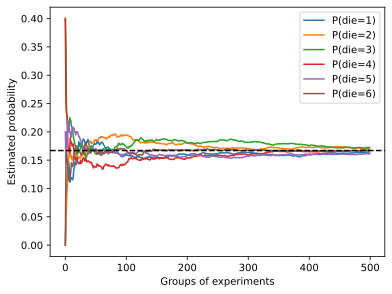

In [12]:

#画大数定律收敛图

#进行500组实验，每组抽取10个样本。
#骰子在每组实验后出现值的估计概率
counts = multinomial.Multinomial(10, fair_probs).sample((500,))
#counts[i, j] = 第 i 组实验里第 j 面出现的次数。​每一行之和 = 10
print(counts.shape)
#cumsum前缀和，沿指定维度做累加，dim=0表示按行累加
cum_counts = counts.cumsum(dim=0)

#keepdims=True 保持除数是 (500,1) 形状，否则是 (500,)导致广播除错
estimates = cum_counts / cum_counts.sum(dim=1, keepdims=True)
d2l.set_figsize((6, 4.5))
for i in range(6):
    d2l.plt.plot(estimates[:, i].numpy(),
                 label=("P(die=" + str(i + 1) + ")"))
d2l.plt.axhline(y=0.167, color='black', linestyle='dashed')
d2l.plt.gca().set_xlabel('Groups of experiments')
d2l.plt.gca().set_ylabel('Estimated probability')
d2l.plt.legend()

#### 随机变量 ————掷骰子实验总结（D2L 2.6）

> 核心就 4 个概念：随机变量、分布、事件、离散 vs 连续

##### 1. 随机变量：给实验结果起个名字

- 掷骰子的结果本来就是 1~6 这几个数，**随机变量 X 就是把"这次掷出来的点数"当成一个量来讨论**
- X 的所有可能取值 = 样本空间 S = {1, 2, 3, 4, 5, 6}
- "掷出一个 5"这个事件，记作 **X = 5**；它的概率记作 **P(X = 5)**&#8203;

> 随机变量 = 实验结果的数量化。有了统一的符号 X，才能讨论 P(X=5)、P(X≤3)、E[X]（期望）

##### 2. 符号简写（三种写法）

| 写法 | 含义 |
|------|------|
| P(X = 5) | 严格写法：X 取值 5 的概率 |
| **P(5)**&#8203; | 简写：省略 X，默认"随机变量取 5 的概率" |
| **P(X)**&#8203; | 不指定具体值，指"X 的**整个分布**" |

对应到骰子：

- **P(X)**&#8203; 就是分布 `[1/6, 1/6, 1/6, 1/6, 1/6, 1/6]` —— 代码里的 `fair_probs` 就是 P(X) 本身
- P(1) = P(2) = ... = P(6) = 1/6

> **"分布" = 一整张"取值 → 概率"的对应表，不是某一个概率，是每个可能取值对应的概率清单。**

##### 3. 事件可以是取值的集合

概率论中**事件 = 一组结果的集合**，除了单点还能问区间：


P(1 ≤ X ≤ 3) = P(1) + P(2) + P(3) = 3/6 = 1/2

##### 4. 离散 vs 连续（本节的关键区别）

> 4.1 离散随机变量（如骰子的每一面）

- 取值**可数**（只有 6 个面）
- 每个取值都有实实在在的概率：P(X = 5) = 1/6
- 单点的概率可以直接问、有意义

> 4.2 连续随机变量（如人的身高、体重）

- 取值**不可数**——测量足够精确时，没有人身高恰好相等
- 问"某人身高**恰好** = 1.80 米"的概率 → **是 0**
- 有意义的问题是"身高落在 **[1.79, 1.81] 这个区间**的概率" → **大于 0**

> 4.3 密度（density）

- 单点概率 = 0，但**密度 ≠ 0**
- 直觉：密度是"概率的**浓度**"
- 区间概率 = 密度 × 区间宽度
- 1.80 处密度高 → 落在 1.80 附近区间的概率大
- 连续分布是一张**连续曲线（密度函数）**&#8203;，不是 6 格概率表

> 4.4 对比表

| | 离散 | 连续 |
|--|------|------|
| 取值 | 可数（6 个面） | 不可数（任意实数） |
| 形态 | 柱状图（6 根柱子） | 一条曲线（密度函数） |
| 单点概率 | 有，如 P(X=5)=1/6 | 恒为 0 |
| 描述工具 | 概率分布表 | 密度函数 |
| 区间概率 | 把区间内各点概率相加 | 曲线下区间面积 |
| 典型例子 | 骰子点数、分类标签 | 身高、体重、温度 |



#### 联合概率
同时发生的概率。  
P (A = a, B = b) ≤ P (A = a)

#### 条件概率
用P (B = b | A = a)表示它:它是B = b的概率，前提是A = a已发生。

#### 贝叶斯概率
P (A, B) = P (B | A)P (A)  = P (A | B)P (B)
$$
P(A \mid B) = \frac{P(B \mid A) \, P(A)}{P(B)}
$$


#### 边际化
$$
P(B) = \sum_{A} P(A, B)
$$

#### 独立性

如果两个随机变量 A 和 B 是**独立的**，意味着事件 A 的发生与事件 B 的发生无关。
记号：
$$
A \perp B
$$

由贝叶斯定理可得：
$$
P(A \mid B) = P(A)
$$

等价推导：
$$
P(A \mid B) = \frac{P(A, B)}{P(B)} = P(A)
$$

移项即得：
$$
P(A, B) = P(A)\,P(B)
$$
> **两个随机变量独立，当且仅当其联合分布等于各自分布的乘积。**&#8203;

不满足上述条件的情况，称 A 和 B **依赖**。


给定另一个随机变量 C 时，A 和 B 是**条件独立**的，当且仅当：

$$
P(A, B \mid C) = P(A \mid C)\,P(B \mid C)
$$

记号：

$$
A \perp B \mid C
$$



### 2.6.3 期望与方差

随机变量 X 的期望（平均值），记作 E[X]：
$$
E[X] = \sum_{x} x \, P(X = x)
$$


**E[X] "每个取值 × 该取值的概率，全部加起来"。**&#8203;

骰子例子：
$$
E[X] = 1 \cdot \tfrac{1}{6} + 2 \cdot \tfrac{1}{6} + \cdots + 6 \cdot \tfrac{1}{6} = \tfrac{21}{6} = 3.5
$$

当函数 f(x) 的输入是从分布 P 中抽取的随机变量时：

$$
E_{x \sim P}[f(x)] = \sum_{x} f(x) \, P(x)
$$


| 符号 | 含义 |
|------|------|
| $E[\cdot]$ | 期望算子（对括号里的东西求平均） |
| $E[X]$ | 随机变量 X 本身的期望 |
| $E_{x \sim P}[f(x)]$ | **下标 $x \sim P$**：声明 x 是从分布 P 中抽样的 |
| 括号里的 $f(x)$ | 被求平均的**对象**——不是 x 本身，而是 x 经过函数 f 之后的值 |

> **下标 $x \sim P$ 说明"x 从哪来"，括号 $f(x)$ 说明"对什么求平均"。**&#8203;
> 当上下文明确时，下标常省略，直接写 E[f(x)]。

和 E[X] 一样：**每个函数值 × 出现概率，再加总**。

$$
E_{x \sim P}[f(x)] = \sum_{x} f(x)\,P(x)
$$

骰子例子，设 f(x) = x²：

$$
E[f(x)] = 1^2 \cdot \tfrac{1}{6} + 2^2 \cdot \tfrac{1}{6} + \cdots + 6^2 \cdot \tfrac{1}{6} = \tfrac{91}{6} \approx 15.17
$$

方差衡量随机变量 X 偏离其期望的程度：

$$
\mathrm{Var}[X] = E\left[(X - E[X])^2\right] = E[X^2] - E[X]^2
$$

**算法一（按定义）**&#8203;：偏差平方的期望

$$
\mathrm{Var}[X] = E\big[(X - E[X])^2\big]
$$

**算法二（计算式）**&#8203;：平方的期望 − 期望的平方

$$
\mathrm{Var}[X] = E[X^2] - E[X]^2
$$

> 注意区分：$E[X^2]$ 是"先平方再求期望"；$E[X]^2$ 是"先求期望再平方"。二者一般不相等！

骰子例子（用算法二）：

$$
\mathrm{Var}[X] = \tfrac{91}{6} - 3.5^2 = 15.17 - 12.25 \approx 2.92
$$


是方差的平方根：

$$
\sigma = \sqrt{\mathrm{Var}[X]}
$$

方差单位是原单位的平方，开方后与 X 同单位，更直观。

随机变量函数的方差

衡量：从分布中采样不同 x 时，**函数值偏离该函数期望的程度**：

$$
\mathrm{Var}[f(x)] = E\left[\big(f(x) - E[f(x)]\big)^2\right]
$$

理解：把 f(x) 看成一个新的随机变量，套用方差定义即可——
先算 f 的期望 E[f(x)]，再算"函数值与该期望之差的平方"的平均。


- **期望 E[X]** = 加权平均（取值 × 概率求和）
  - E[f(x)]：函数值的加权平均，公式同构：Σ f(x)P(x)
  - E 的下标 x∼P：说明 x 从分布 P 抽样；括号里：求平均的对象
- **方差 Var[X]** = 偏离期望程度的度量
  - 定义式：E[(X − E[X])²]
  - 计算式：E[X²] − E[X]²（先平方的期望 − 期望的平方）
- **标准差** = √方差（与原变量同单位）
- **Var[f(x)]**：函数值波动程度的度量


### 